# **Random Forest Tree Model: Box Office Revenue Prediction**
### Ciaran O' Toole - C00297672
##### A portfolio produced as part of the Data Science & Machine Learning 1 Module in SE603, Bachelor of Science (Honours) Software Development at SETU

This notebook marks the next modelling stage of my portfolio after decision trees, focusing on building, training, and evaluating a baseline **Random Forest Tree** model using my currated and verified dataset of 902 movies prepared in `Datasetcleansing.ipynb` and stored in `movies.csv`. The objective is to investigate whether a movie's production budget alone can accurately predict its worldwide box office revenue.

### **Step 1 - Data Loading & Exploration**

I load `movies.csv`, format the summary statistics in USD so they are easy to read, and plot production budget against box office revenue to verify the dataset before training.

                budget            revenue
count              902                902
mean    $84,527,724.89    $358,984,207.31
std     $80,971,676.04    $391,637,304.33
min         $35,000.00         $55,240.00
25%     $19,000,000.00     $77,500,895.25
50%     $60,000,000.00    $239,853,665.00
75%    $138,500,000.00    $504,762,554.75
max    $658,800,000.00  $2,942,649,778.00


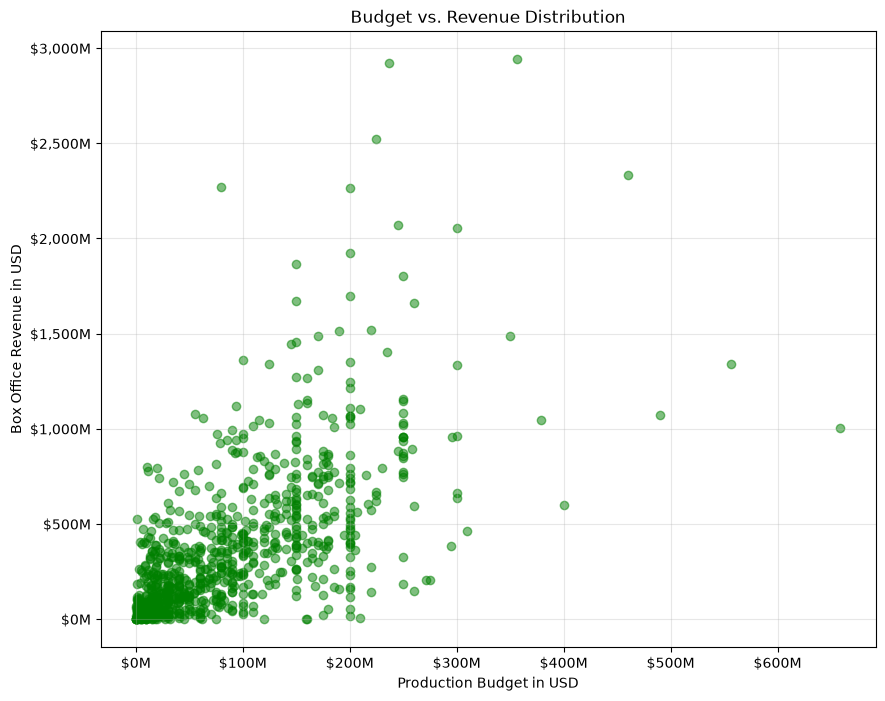

In [1]:
import matplotlib.pyplot as plot
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pand

# load dataset
movies = pand.read_csv("movies.csv")

# format summary statistics as dollars instead of scientific notation
stats = movies[["budget", "revenue"]].describe().astype(object)

for row in stats.index:
  if row == "count":
    stats.loc[row, "budget"] = f"{int(stats.loc[row, 'budget'])}"
    stats.loc[row, "revenue"] = f"{int(stats.loc[row, 'revenue'])}"
  else:
    stats.loc[row, "budget"] = f"${stats.loc[row, 'budget']:,.2f}"
    stats.loc[row, "revenue"] = f"${stats.loc[row, 'revenue']:,.2f}"

print(stats)

# display axes in Millions
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")

plot.figure(figsize=(10, 8))
plot.scatter(movies["budget"], movies["revenue"], alpha=0.5, color="green")

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.xlabel("Production Budget in USD")
plot.ylabel("Box Office Revenue in USD")
plot.title("Budget vs. Revenue Distribution")
plot.grid(True, alpha=0.3)
plot.show()